# Part 1 EDA


In [30]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import squarify

In [6]:
df = pd.read_csv('laptop_data_cleaned.csv')
df.head()

,Brand,Product Name,CPU,CPU Vendor,CPU Family,GPU,GPU Vendor,GPU Family,GPU Type,RAM (GB),SSD (GB),Screen Size (inch),Price (VND),Rating,Sold Count
0,HP,Laptop HP 240R G10,Intel Core 5 Raptor Lake 120U,Intel,Intel Core 5,Intel UHD Graphics,Intel,Intel UHD,Integrated,16.0,512.0,14.0,21290000.0,4.9,5902.0
1,ASUS,Laptop Asus Vivobook 14 X1404VA,Intel Core 3 Raptor Lake 100U,Intel,Intel Core 3,Intel UHD Graphics,Intel,Intel UHD,Integrated,8.0,256.0,14.0,15590000.0,5.0,76.0
2,HP,Laptop HP 15 fc0023AU,AMD Ryzen 5 7520U,AMD,AMD Ryzen 5,AMD Radeon 610M Graphics,AMD,AMD Radeon,Integrated,16.0,512.0,15.6,21090000.0,4.9,8001.0
3,Apple,MacBook Air 13 inch M5 16GB/512GB/8GPU 30W,Apple M5,Apple,Apple M5,Integrated GPU - 8 cores,Apple,Apple GPU,Integrated,16.0,512.0,13.6,33390000.0,5.0,7.0
4,Dell,Laptop Dell 15 DC15250,Intel Core i5 Raptor Lake 1334U,Intel,Intel Core i 5,Intel UHD Graphics,Intel,Intel UHD,Integrated,16.0,512.0,15.6,22990000.0,5.0,3906.0


# 1. Dataset Overview

In [7]:
total_rows = len(df)
total_columns = len(df.columns)

total_products = df["Product Name"].nunique()
total_brands = df['Brand'].nunique()

print(f'Total Rows:{total_rows}')
print(f"Total Columns:{total_columns}")
print(f"Total Products:{total_products}")
print(f"Total Brands:{total_brands}")

Total Rows:438
Total Columns:15
Total Products:286
Total Brands:10


# 2. Brand Analysis

In [8]:
# Convert to Milion VND
df["Price (Milion VND)"] = df["Price (VND)"] / 1_000_000

In [9]:
# Analyze the level of appearance of each brand
brand_analysis = (
    df.groupby("Brand").agg(
        Product_Count = ("Product Name", "nunique"),
        Average_Price = ("Price (Milion VND)", "mean"),
        Minimum_Price = ("Price (Milion VND)", "min"),
        Maximum_Price = ("Price (Milion VND)", "max")

    )
    .assign(
        Market_Share = lambda x:x["Product_Count"] / x["Product_Count"].sum() *100
    )
    .sort_values("Product_Count", ascending=False)
    .reset_index()
)

brand_analysis = brand_analysis.rename(columns={
    "Average_Price":"Average_Price (VND)",
    "Minimum_Price": "Minimum_Price (VND)",
    "Maximum_Price": "Maxiumum_Price (VND)",
    "Market_Share": "Market_Share (VND)"
})

display(brand_analysis.round(2))


,Brand,Product_Count,Average_Price (VND),Minimum_Price (VND),Maxiumum_Price (VND),Market_Share (VND)
0,HP,65,31.36,19.49,62.79,22.73
1,ASUS,63,38.20,15.59,188.99,22.03
2,Lenovo,57,41.18,16.99,129.29,19.93
3,Acer,36,34.87,15.49,149.29,12.59
4,Dell,20,28.95,18.99,54.29,6.99
5,MSI,18,47.40,26.99,85.99,6.29
6,Apple,17,65.13,19.19,123.99,5.94
7,Gigabyte,6,38.07,29.49,54.99,2.10
8,Thunderobot,3,18.99,13.59,24.79,1.05
9,SingPC,1,15.94,13.69,18.19,0.35


# 3. Price Analysis

In [10]:
price_analysis = df["Price (Milion VND)"].describe()
print(price_analysis)

count    438.000000
mean      37.046849
std       20.822348
min       13.590000
25%       24.915000
50%       30.990000
75%       40.965000
max      188.990000
Name: Price (Milion VND), dtype: float64


In [11]:
# Analyze the price of the laptop market
price_analysis = df["Price (Milion VND)"].describe()

print("PRICE ANALYSIS")
print("=" * 50)

print(f"Count: {price_analysis['count']:,.0f}")
print(f"Average Price: {price_analysis['mean']:,.2f} Million VND")
print(f"Median Price: {price_analysis['50%']:,.2f} Million VND")
print(f"Minimum Price: {price_analysis['min']:,.2f} Million VND")
print(f"Maximum Price: {price_analysis['max']:,.2f} Million VND")
print(f"Q1 (25%): {price_analysis['25%']:,.2f} Million VND")
print(f"Q3 (75%): {price_analysis['75%']:,.2f} Million VND")
print(f"IQR: {price_analysis['75%'] - price_analysis['25%']:,.2f} Million VND")
print(f"Standard Deviation: {price_analysis['std']:,.2f} Million VND")


PRICE ANALYSIS
Count: 438
Average Price: 37.05 Million VND
Median Price: 30.99 Million VND
Minimum Price: 13.59 Million VND
Maximum Price: 188.99 Million VND
Q1 (25%): 24.91 Million VND
Q3 (75%): 40.97 Million VND
IQR: 16.05 Million VND
Standard Deviation: 20.82 Million VND


In [12]:
# Analysis by brand
brand_price = (
    df.groupby("Brand")["Price (Milion VND)"]
    .agg(["count", "mean", "median", "min", "max"])
    .sort_values("mean", ascending=False)
)

display(brand_price.round(0))

,count,mean,median,min,max
Brand,,,,,
Apple,17,65.0,55.0,19.0,124.0
MSI,21,47.0,42.0,27.0,86.0
Lenovo,87,41.0,34.0,17.0,129.0
ASUS,96,38.0,29.0,16.0,189.0
Gigabyte,12,38.0,37.0,29.0,55.0
Acer,60,35.0,30.0,15.0,149.0
HP,76,31.0,30.0,19.0,63.0
Dell,64,29.0,28.0,19.0,54.0
Thunderobot,3,19.0,19.0,14.0,25.0


# 4. RAM & SSD Analysis

In [13]:
# Analysis by brand
ram_analysis = (
    df.groupby("RAM (GB)")
    .size()
    .reset_index(name="Product_Count")
    .assign(
        percentage = lambda x : x['Product_Count'] / x['Product_Count'].sum() *100
    )
    .sort_values("Product_Count", ascending=False)
)

ram_analysis = ram_analysis.rename(columns={
    "percentage": "percentage (%)"
})

display(ram_analysis.round(2))

,RAM (GB),Product_Count,percentage (%)
2,16.0,304,69.41
0,8.0,50,11.42
4,32.0,49,11.19
3,24.0,19,4.34
7,64.0,5,1.14
5,36.0,4,0.91
1,12.0,3,0.68
6,48.0,2,0.46
8,128.0,1,0.23
9,192.0,1,0.23


In [14]:
# SDD Analysis 

ssd_analysis = (
    df.groupby("SSD (GB)")
    .size()
    .reset_index(name="Product_Count")
    .assign(
        Percentage=lambda x: x["Product_Count"] / x["Product_Count"].sum() * 100
    )
    .sort_values("Product_Count",ascending=False)

)

ssd_analysis = ssd_analysis.rename(columns={
    "Percentage": "Percentage (%)"
})

display(ssd_analysis.round(2))

,SSD (GB),Product_Count,Percentage (%)
1,512.0,329,75.11
2,1024.0,83,18.95
3,2048.0,21,4.79
0,256.0,5,1.14


In [15]:
# combine ssd and ram 
ram_ssd_analysis = pd.crosstab(
    df["RAM (GB)"],
    df["SSD (GB)"]
)
display(ram_ssd_analysis)

SSD (GB),256.0,512.0,1024.0,2048.0
RAM (GB),,,,
8.0,5,45,0,0
12.0,0,3,0,0
16.0,0,248,43,13
24.0,0,12,7,0
32.0,0,21,26,2
36.0,0,0,1,3
48.0,0,0,2,0
64.0,0,0,3,2
128.0,0,0,1,0


# 5. CPU Analysis

In [16]:
# CPU Analysis
cpu_analysis = (
    df.groupby("CPU Family")
    .agg(
        Product_Count=("Product Name", "nunique"),
        Average_Price=("Price (VND)", "mean"),
        Median_Price=("Price (VND)", "median")
    )
    .assign(
        Percentage=lambda x: x["Product_Count"] / x["Product_Count"].sum() * 100
    )
    .sort_values("Product_Count", ascending=False)
    .reset_index()
)

# Format for display
cpu_display = cpu_analysis.copy()

cpu_display[["Average_Price", "Median_Price"]] = (
    cpu_display[["Average_Price", "Median_Price"]] / 1_000_000
)

cpu_display = cpu_display.rename(columns={
    "Average_Price": "Average_Price (VND)",
    "Median_Price": "Median_Price (VND)",
    "Percentage": "Percentage (%)"
})

display(cpu_display.round(2))

,CPU Family,Product_Count,Average_Price (VND),Median_Price (VND),Percentage (%)
0,Intel Core Ultra 7,50,43.67,37.74,14.25
1,Intel Core Ultra 5,50,31.70,30.09,14.25
2,Intel Core 5,40,26.42,25.49,11.40
3,Intel Core i 5,27,29.15,27.99,7.69
4,Intel Core i 7,25,35.23,33.99,7.12
5,Intel Core 7,25,32.27,31.84,7.12
6,AMD Ryzen 7,24,31.68,30.54,6.84
7,AMD Ryzen 5,15,21.85,20.74,4.27
8,Intel Core Ultra 9,14,69.58,58.99,3.99
9,AMD Ryzen AI 7,13,36.84,34.99,3.70


In [17]:
# Analysis by CPU manufacturer
cpu_vendor_analysis  =(
    df.groupby("CPU Vendor")
    .agg(
        Product_Count = ("Product Name","nunique"),
        Average_Price = ("Price (VND)","mean")
    )
        .assign(
        Percentage=lambda x: x["Product_Count"] / x["Product_Count"].sum() * 100
    )
    .sort_values("Product_Count",ascending=False)
    .reset_index()
)

cpu_vendor_analysis[["Average_Price"]] = (
    cpu_vendor_analysis[["Average_Price"]] / 1_000_000
)

cpu_vendor_analysis = cpu_vendor_analysis.rename(columns={
    "Average_Price": "Average_Price (VND)",
    "Percentage": "Percentage (%)"
})

display(cpu_vendor_analysis.round(2))

,CPU Vendor,Product_Count,Average_Price (VND),Percentage (%)
0,Intel,196,35.28,68.06
1,AMD,65,32.75,22.57
2,Apple,17,65.13,5.90
3,Qualcomm,7,34.86,2.43
4,NVIDIA,3,134.05,1.04


In [18]:
# Analyze GPU lines on the market.
gpu_analysis = (
    df.groupby("GPU Family")
    .agg(
        Product_Count=("Product Name", "nunique"),
        Average_Price=("Price (VND)", "mean"),
        Median_Price=("Price (VND)", "median")
    )
    .assign(
        Percentage=lambda x: x["Product_Count"] / x["Product_Count"].sum() * 100
    )
    .sort_values("Product_Count", ascending=False)
    .reset_index()
)

gpu_analysis[["Average_Price","Median_Price"]] = (
    gpu_analysis[["Average_Price","Median_Price"]] /1_000_000
)

gpu_analysis = gpu_analysis.rename(columns={
    "Average_Price": "Average_Price (VND)",
    "Median_Price": "Median_Price (VND)",
    "Percentage": "Percentage (%)"

})

display(gpu_analysis.round(2))

,GPU Family,Product_Count,Average_Price (VND),Median_Price (VND),Percentage (%)
0,Intel Graphics,87,31.99,29.19,28.52
1,NVIDIA GeForce RTX,84,44.35,39.99,27.54
2,AMD Radeon,38,27.47,25.89,12.46
3,Intel Arc,31,42.40,36.39,10.16
4,Apple GPU,17,65.13,54.99,5.57
5,Intel UHD,16,23.71,23.49,5.25
6,Integrated Graphics,12,33.96,27.59,3.93
7,Intel Iris Xe,8,22.53,21.99,2.62
8,Qualcomm Adreno,7,34.86,29.29,2.30
9,NVIDIA Blackwell,3,134.05,124.99,0.98


# Part 2 Data Visualization


In [19]:
sns.set_theme(style="whitegrid",palette="Set2")
plt.rcParams["figure.figsize"] = (10,6)
plt.rcParams["axes.titlesize"] = 14
plt.rcParams["axes.labelsize"] = 11
plt.rcParams["font.size"] = 10

# 1. Brand Analysis

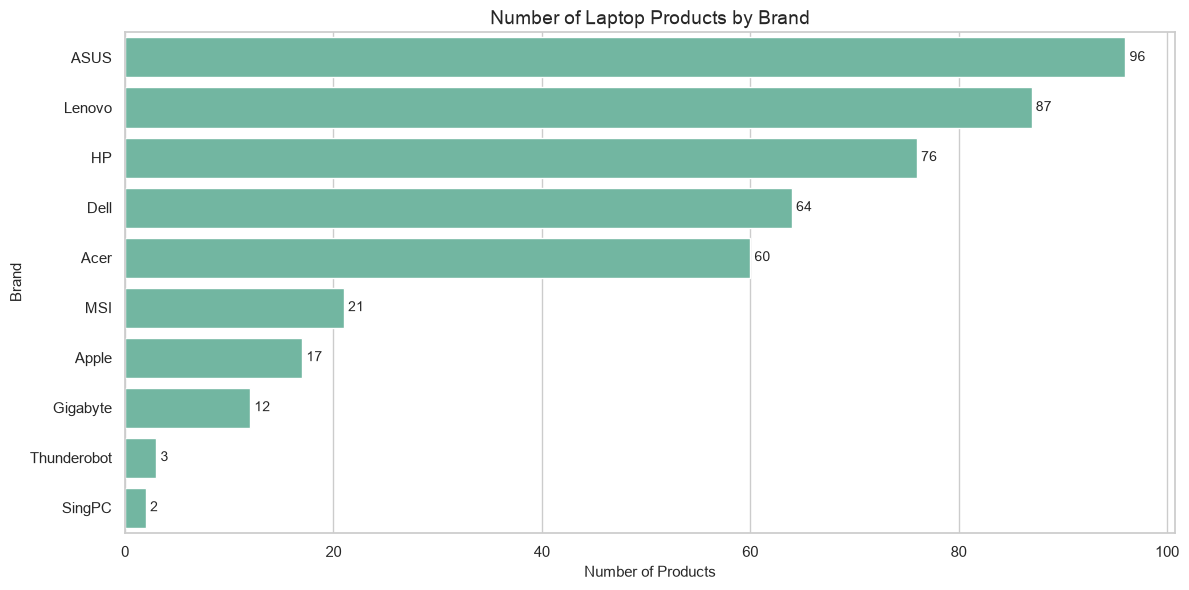

In [20]:
brand_counts = (
    df["Brand"]
    .value_counts()
    .reset_index()
)

brand_counts.columns = ["Brand", "Product_Count"]

brand_counts = brand_counts.sort_values(
    "Product_Count",
    ascending=False
)

plt.figure(figsize=(12, 6))

ax = sns.barplot(
    data=brand_counts,
    x="Product_Count",
    y="Brand"
)

for container in ax.containers:
    ax.bar_label(container, padding=3)

plt.title("Number of Laptop Products by Brand")
plt.xlabel("Number of Products")
plt.ylabel("Brand")

plt.tight_layout()
plt.show()

### Brand Analysis – Number of Laptop Products by Brand

Based on 438 laptop listings collected from an e-commerce website, ASUS leads with 96 products, followed by Lenovo (87), HP (76), Dell (64), and Acer (60). These five brands have the highest product representation in the collected dataset.

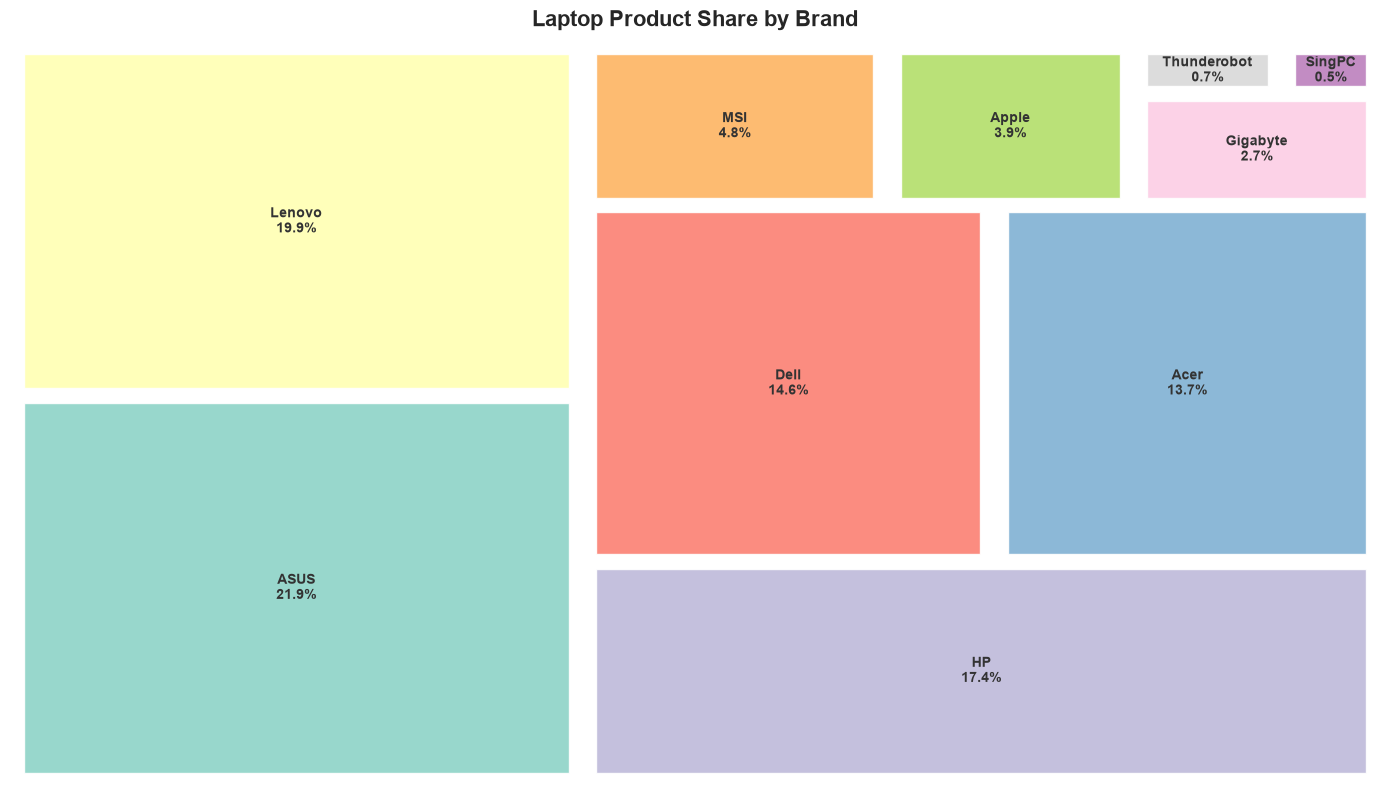

In [ ]:
plt.figure(figsize=(14, 8))

# Sort data by Product Count
data = brand_counts.sort_values(
    "Product_Count",
    ascending=False
)

# Create labels
labels = [
    f"{brand}\n{share:.1f}%"
    for brand, share in zip(
        data["Brand"],
        data["Market_Share"]
    )
]

# Pastel color palette
colors = plt.cm.Set3(
    range(len(data))
)

# Create Treemap
squarify.plot(
    sizes=data["Product_Count"],
    label=labels,
    color=colors,
    alpha=0.9,
    pad=True,
    text_kwargs={
        "fontsize": 10,
        "weight": "bold",
        "color": "#333333"
    }
)

plt.title(
    "Laptop Product Share by Brand",
    fontsize=16,
    fontweight="bold",
    pad=15
)

plt.axis("off")
plt.tight_layout()
plt.show()

### Brand Analysis – Laptop Product Share by Brand

ASUS has the largest product share (21.9%), followed by Lenovo (19.9%) and HP (17.4%). The top five brands account for 87.5% of all collected listings, indicating a strong concentration of product representation among these brands. Meanwhile, smaller brands such as Gigabyte, Thunderobot, and SingPC have limited representation.

# 2. Price Analysis

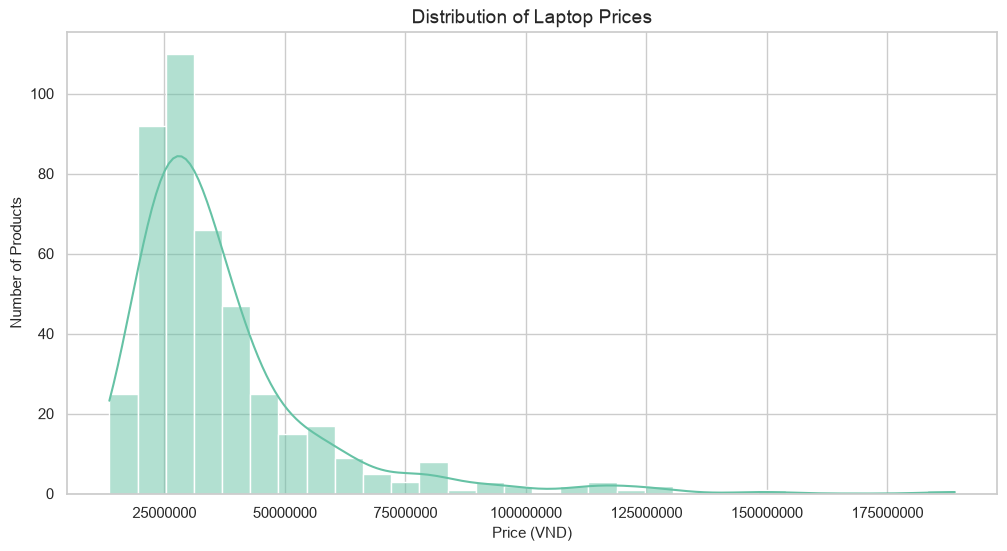

In [ ]:
# Price Analysis

plt.figure(figsize=(12,6))

sns.histplot(
    data=df,
    x="Price (VND)",
    bins=30,
    kde=True
)

plt.title("Distribution of Laptop Prices")
plt.xlabel("Price (VND)")
plt.ylabel("Number of Products")

plt.ticklabel_format(
    style='plain',
    axis="x"
)

### Price Analysis – Distribution of Laptop Prices

Most laptop listings are concentrated between 20 and 45 million VND, with the highest frequency around 25–30 million VND. The distribution is positively skewed, indicating fewer high-priced laptops. A small number of premium models are priced above 75 million VND.

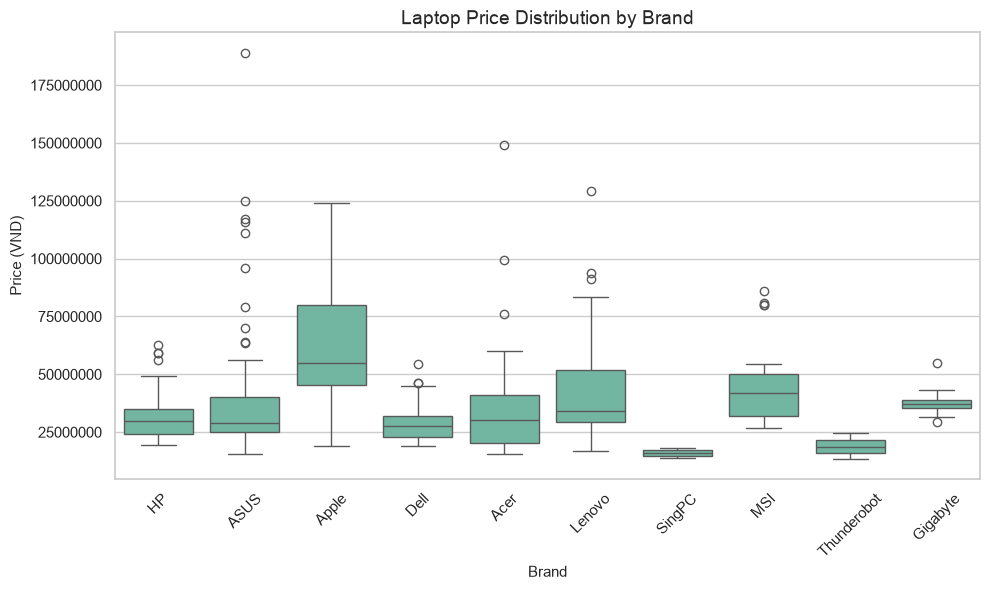

In [ ]:
# compare laptop prices between brands 
plt.Figure(figsize=(13,7))

sns.boxplot(
    data=df,
    x="Brand",
    y="Price (VND)"
)

plt.title("Laptop Price Distribution by Brand")
plt.xlabel("Brand")
plt.ylabel("Price (VND)")

plt.xticks(rotation=45)
plt.ticklabel_format(style="Plain",axis="y")

plt.tight_layout()
plt.show()

### Price Analysis – Laptop Price Distribution by Brand

Apple has the highest median laptop price (approximately 55 million VND), while SingPC and Thunderobot occupy the lowest price segments. ASUS, Acer, and Lenovo show greater price variability, with several high-priced outliers. Overall, laptop pricing varies considerably across brands.

# 4. Ram & SSD Analysis

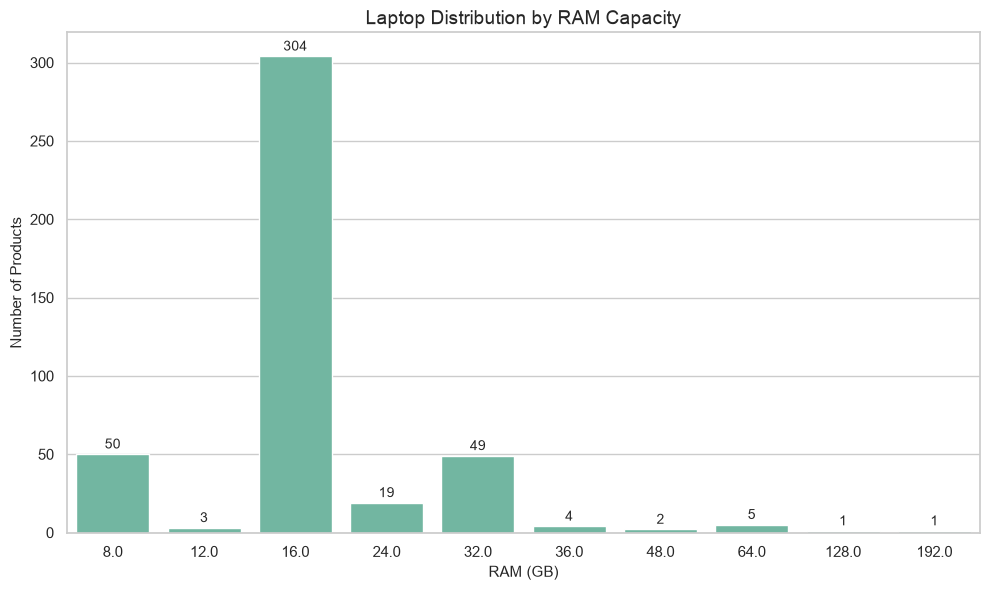

In [ ]:
# Distribution of Ram
ram_count = (
    df["RAM (GB)"]
    .value_counts()
    .sort_index()
    .reset_index()
)

ram_count.columns = ["RAM (GB)","Product_Count"]
plt.figure(figsize=(10,6))
ax = sns.barplot(
    data = ram_count,
    x = "RAM (GB)",
    y = "Product_Count"
)

for container in ax.containers:
    ax.bar_label(
        container,
        labels=[f"{bar.get_height():.0f}" for bar in container],
        padding=2
    )

plt.title("Laptop Distribution by RAM Capacity")
plt.xlabel("RAM (GB)")
plt.ylabel("Number of Products")

plt.tight_layout()
plt.show()

### RAM Analysis – Laptop Distribution by RAM Capacity

16GB RAM dominates the dataset with 304 listings, followed by 8GB (50) and 32GB (49). This indicates a strong concentration of laptop listings around the 16GB configuration, while higher-capacity options (64GB and above) are relatively limited.

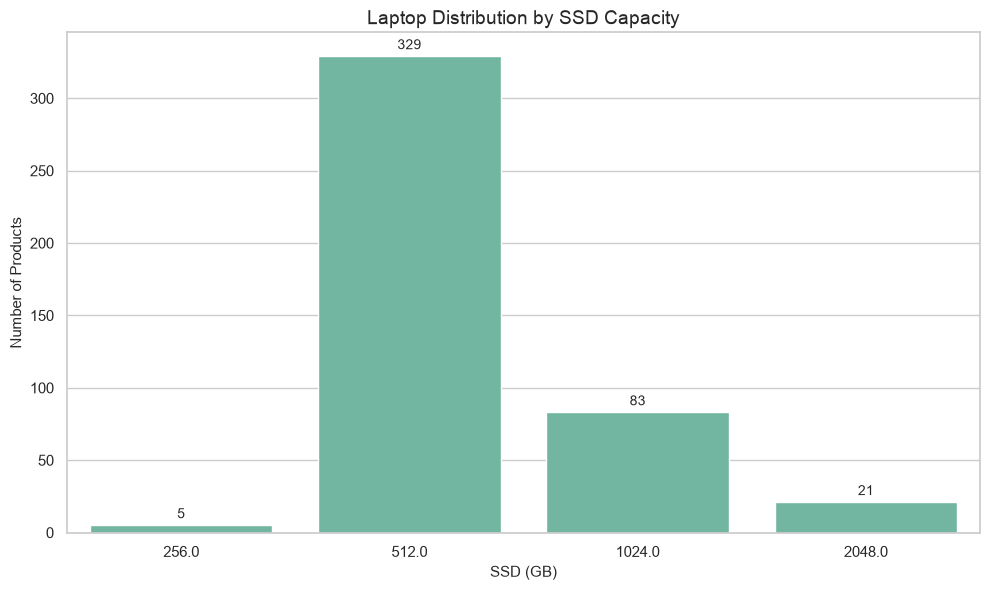

In [ ]:
# SSD capacity distribution

ssd_counts = (
    df["SSD (GB)"]
    .value_counts()
    .sort_index()
    .reset_index()
)

ssd_counts.columns = ["SSD (GB)","Product_Count"]
plt.Figure(figsize=(10,6))

ax = sns.barplot(
    data = ssd_counts,
    x = "SSD (GB)",
    y = "Product_Count"
)

for container in ax.containers:
    ax.bar_label(container,padding=3)

plt.title("Laptop Distribution by SSD Capacity")
plt.xlabel("SSD (GB)")
plt.ylabel("Number of Products")
plt.tight_layout()
plt.show()

### SSD Analysis – Laptop Distribution by SSD Capacity

512GB SSD dominates the dataset with 329 listings, followed by 1TB (83) and 2TB (21). This indicates a strong concentration of laptop listings with 512GB storage, while other SSD configurations are less represented.

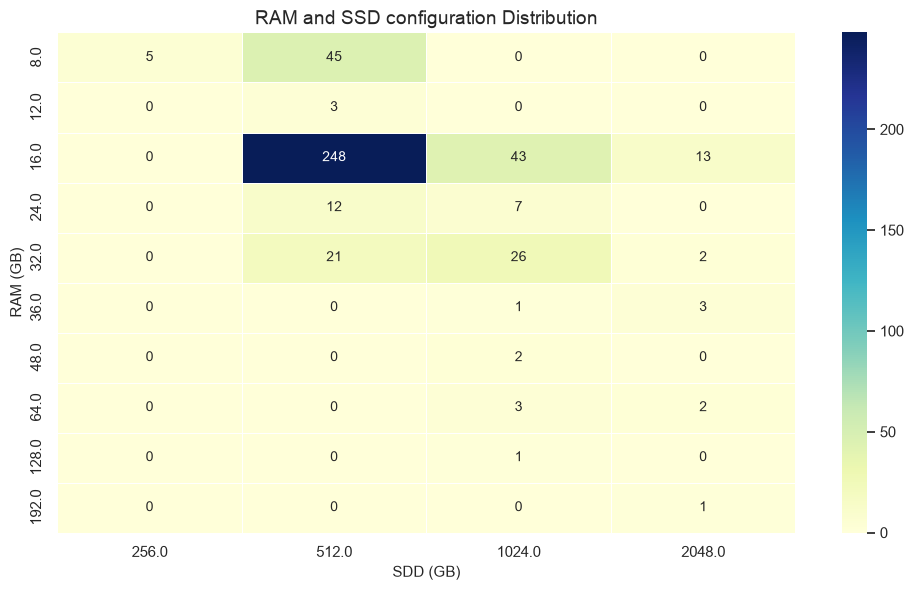

In [ ]:
# Combine SSD and SDD

ram_ssd = pd.crosstab(
    df["RAM (GB)"],
    df["SSD (GB)"]
)

plt.Figure(figsize=(12,7))

sns.heatmap(
    ram_ssd,
    annot= True,
    fmt = "d",
    cmap= "YlGnBu",
    linewidths=0.5
)

plt.title("RAM and SSD configuration Distribution")
plt.xlabel("SDD (GB)")
plt.ylabel("RAM (GB)")

plt.tight_layout()
plt.show()

### RAM and SSD Analysis – Configuration Distribution

The 16GB RAM + 512GB SSD configuration dominates the dataset with 248 listings. Overall, 16GB RAM is the most common configuration, while 512GB SSD is the predominant storage capacity. Higher-end configurations are relatively limited.

# 5. CPU Analysis

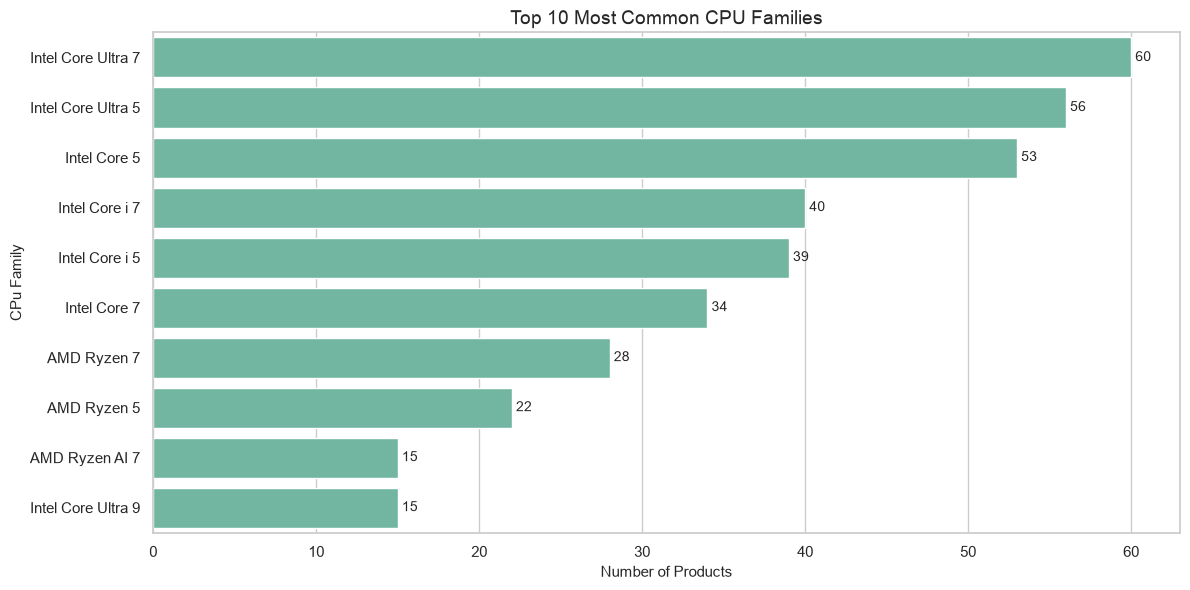

In [ ]:


cpu_counts = (
    df["CPU Family"]
    .value_counts()
    .head(10)
    .reset_index()
)

cpu_counts.columns = ["CPU Family","Product_Count"]

plt.figure(figsize=(12,6))

ax = sns.barplot(
data = cpu_counts,
x = "Product_Count",
y = "CPU Family"
)

for container in ax.containers:
    ax.bar_label(container, padding=3)


plt.title("Top 10 Most Common CPU Families")
plt.xlabel("Number of Products")
plt.ylabel("CPu Family")

plt.tight_layout()
plt.show()

### CPU Analysis – Top 10 Most Common CPU Families

Intel dominates the top 10 CPU families, with Intel Core Ultra 7 leading at 60 listings, followed by Core Ultra 5 (56) and Core 5 (53). AMD Ryzen families have lower representation, with Ryzen 7 leading among AMD models at 28 listings.

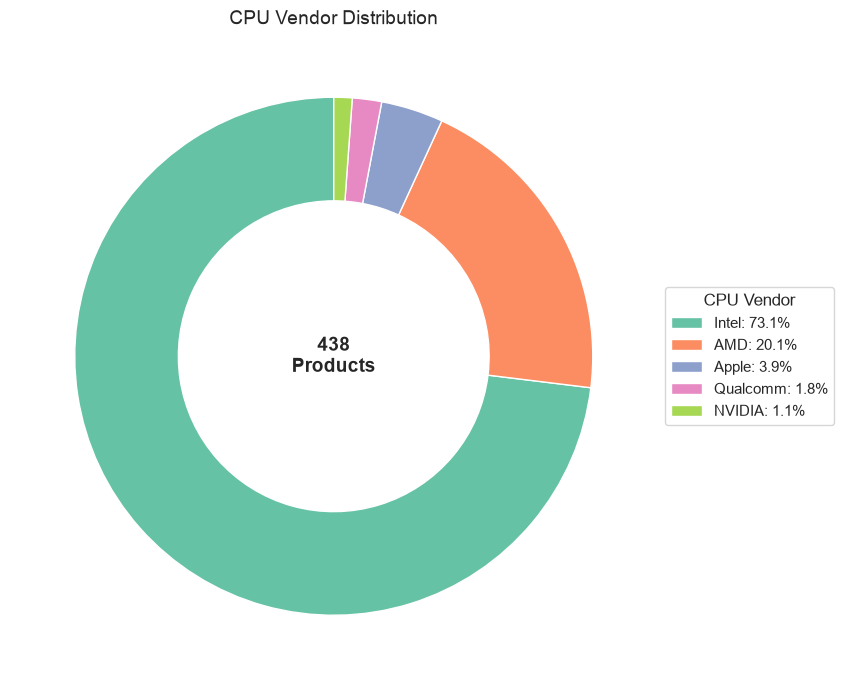

In [45]:
# Intel and AMD

cpu_vendor = (
    df["CPU Vendor"]
    .value_counts()
    .reset_index()
)

cpu_vendor.columns = ["CPU Vendor", "Product_Count"]

# Calculate percentage
cpu_vendor["Percentage"] = (
    cpu_vendor["Product_Count"]
    / cpu_vendor["Product_Count"].sum() * 100
)

plt.figure(figsize=(10, 7))

wedges, texts = plt.pie(
    cpu_vendor["Product_Count"],
    labels=None,
    autopct=None,
    startangle=90,
    wedgeprops=dict(
        width=0.4,
        edgecolor="white"
    )
)

# Add total products in the center
total = cpu_vendor["Product_Count"].sum()

plt.text(
    0, 0,
    f"{total}\nProducts",
    ha="center",
    va="center",
    fontsize=14,
    fontweight="bold"
)

# Legend with all percentages
legend_labels = [
    f"{vendor}: {percentage:.1f}%"
    for vendor, percentage in zip(
        cpu_vendor["CPU Vendor"],
        cpu_vendor["Percentage"]
    )
]

plt.legend(
    wedges,
    legend_labels,
    title="CPU Vendor",
    loc="center left",
    bbox_to_anchor=(1, 0.5)
)

plt.title("CPU Vendor Distribution")

plt.tight_layout()
plt.show()

### CPU Analysis – CPU Vendor Distribution

Intel dominates the dataset with 73.1% of listings, followed by AMD at 20.1%. Apple, Qualcomm, and NVIDIA account for only 6.8% combined, indicating Intel's strong product representation among the collected laptop listings.

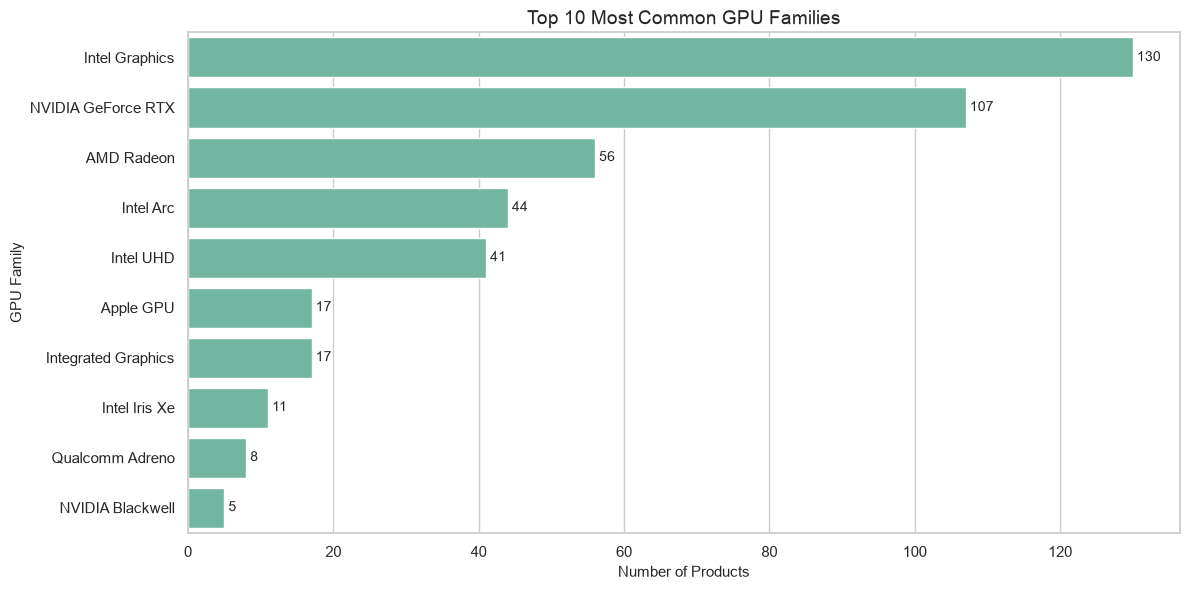

In [ ]:
# Top 10 GPU most popular
gpu_counts = (
    df["GPU Family"]
    .value_counts()
    .head(10)
    .reset_index()
)

gpu_counts.columns = ["GPU Family", "Product_Count"]

plt.figure(figsize=(12, 6))

ax = sns.barplot(
    data=gpu_counts,
    x="Product_Count",
    y="GPU Family"
)

for container in ax.containers:
    ax.bar_label(container, padding=3)

plt.title("Top 10 Most Common GPU Families")
plt.xlabel("Number of Products")
plt.ylabel("GPU Family")

plt.tight_layout()
plt.show()

### GPU Analysis – Top 10 Most Common GPU Families

Intel Graphics leads the dataset with 130 listings, followed by NVIDIA GeForce RTX (107) and AMD Radeon (56). Intel-based graphics families have strong representation, while NVIDIA GeForce RTX is the most common dedicated GPU family among the top 10.